In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_classification

## Dataset tayyorlash


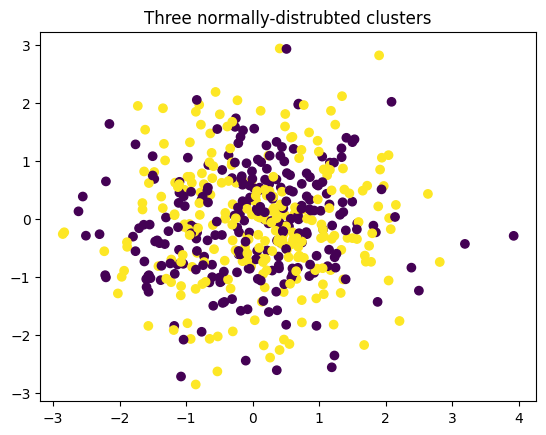

In [ ]:
X,y = make_classification(n_samples=500, n_features=20, n_classes=2, random_state=42)
plt.scatter(X[:,0], X[:,1], c=y)
plt.title("Three normally-distrubted clusters")
plt.show()

In [ ]:
X.shape

(500, 20)

In [ ]:
X[:2]

array([[-0.20367375, -0.22647889,  1.22693322, -0.82688035, -0.01414964,
        -0.5822391 , -0.60221206,  1.66125921, -0.99838544,  0.76608028,
         0.36736551, -0.10015408, -0.45709626,  0.46877426,  0.91358463,
        -0.5286394 , -0.87798259,  0.3017919 , -0.80317895, -0.67828627],
       [ 1.33665736,  1.22129495, -0.89542796,  0.32021658,  0.20260752,
         0.08188754,  0.18497058,  0.57645135,  1.70732981, -1.27835263,
         0.13395838, -1.3365685 , -1.50855597,  0.45275635, -0.09511165,
        -1.37483612,  1.5486393 , -0.7708188 , -0.33303762,  0.75115426]])

In [ ]:
y.shape

(500,)

In [ ]:
y[:5]

array([0, 0, 0, 1, 0])

In [ ]:
x0=np.ones((len(y),1))
x0.shape

(500, 1)

In [ ]:
x0[:5]

array([[1.],
       [1.],
       [1.],
       [1.],
       [1.]])

In [ ]:
X = np.hstack((x0, X))
print(f"O'zgargan X matrtisamiz shakli: {X.shape}")
y = y.reshape(len(y), 1)
print(f"O'zgargan y matrtisamiz shakli: {y.shape}")

O'zgargan X matrtisamiz shakli: (500, 21)
O'zgargan y matrtisamiz shakli: (500, 1)


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shakli: {X_train.shape}")
print(f"X_test shakli: {X_test.shape}")
print(f"y_train shakli: {y_train.shape}")
print(f"y_test shakli: {y_test.shape}")

X_train shakli: (400, 21)
X_test shakli: (100, 21)
y_train shakli: (400, 1)
y_test shakli: (100, 1)


In [ ]:
def sigmoid(z):
  return 1/(1 + np.exp(-z))

a = sigmoid(0)
print(a)

0.5


In [ ]:
lr = 0.1
iterations = 1000
Loss = []

m,n = X_train.shape
theta = np.zeros((n,1))

for iter in range(iterations):
  # oldinga tarqalish
  z = np.dot(X_train, theta)
  h_x = sigmoid(z)
  error = h_x - y_train

  # Xatolik funksiyasi
  loss = -np.sum((y_train * np.log(h_x) + ((1-y_train) * np.log(1-h_x))))/m
  Loss.append(loss)

  # Gradient descent, orqaga tarqalish
  theta = theta - lr * (1/m) * np.dot(X_train.T, error)
  if iter%100 ==0:
    print(f"Iteratsiya: {iter}, Loss qiymati: {loss}")
print("==="*10)
print(f"O'zgaruvchi theta: \n{theta}")


Iteratsiya: 0, Loss qiymati: 0.6931471805599452
Iteratsiya: 100, Loss qiymati: 0.30561444789920134
Iteratsiya: 200, Loss qiymati: 0.28696147788610354
Iteratsiya: 300, Loss qiymati: 0.28177401464986757
Iteratsiya: 400, Loss qiymati: 0.27979600157590884
Iteratsiya: 500, Loss qiymati: 0.2789304541174049
Iteratsiya: 600, Loss qiymati: 0.2785220787048279
Iteratsiya: 700, Loss qiymati: 0.27832033456596417
Iteratsiya: 800, Loss qiymati: 0.2782176417911783
Iteratsiya: 900, Loss qiymati: 0.27816429828418593
O'zgaruvchi theta: 
[[-0.18800957]
 [ 0.339902  ]
 [ 0.23328779]
 [ 0.00956632]
 [ 0.02085264]
 [-0.24427714]
 [ 0.63154409]
 [ 0.35124322]
 [-0.11501286]
 [ 0.20272252]
 [-0.06015096]
 [ 0.04620764]
 [-0.15464964]
 [-0.01297895]
 [-0.36894415]
 [ 0.07729783]
 [ 2.44883885]
 [-0.09525049]
 [-0.16871317]
 [-0.05730788]
 [-0.11291159]]


Text(0, 0.5, 'Loss')

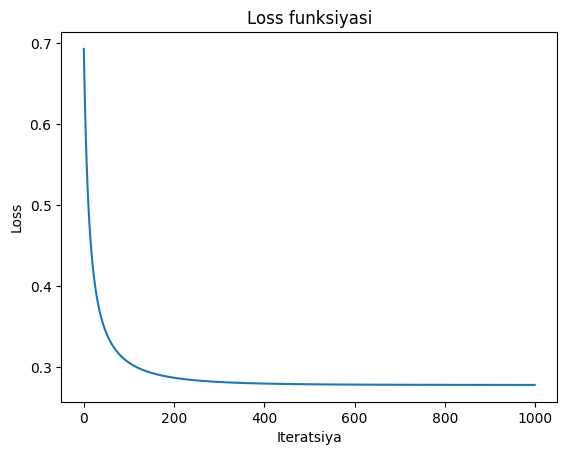

In [ ]:
plt.plot(Loss)
plt.title("Loss funksiyasi")
plt.xlabel("Iteratsiya")
plt.ylabel("Loss")

In [ ]:
## BASHORAT QILISH
def prediction(X_test, theta):
  z = np.dot(X_test, theta)
  h_x = sigmoid(z)
  if h_x[0][0] >= 0.5:
    pred=1
  else:
    pred=0
  return pred

In [ ]:
my_pred = []
for indx in range(len(y_test)):
    label = y_test[indx]
    test_sample = X_test[indx].reshape(1, -1)
    pred = prediction(X_test=test_sample, theta=theta)
    my_pred.append(pred)
    print(f"Mening modelim bashorati -> {pred}, ---> Asl qiymat -> {label}")


Mening modelim bashorati -> 0, ---> Asl qiymat -> [0]
Mening modelim bashorati -> 0, ---> Asl qiymat -> [0]
Mening modelim bashorati -> 0, ---> Asl qiymat -> [0]
Mening modelim bashorati -> 0, ---> Asl qiymat -> [0]
Mening modelim bashorati -> 0, ---> Asl qiymat -> [0]
Mening modelim bashorati -> 1, ---> Asl qiymat -> [1]
Mening modelim bashorati -> 1, ---> Asl qiymat -> [1]
Mening modelim bashorati -> 1, ---> Asl qiymat -> [0]
Mening modelim bashorati -> 1, ---> Asl qiymat -> [1]
Mening modelim bashorati -> 0, ---> Asl qiymat -> [0]
Mening modelim bashorati -> 0, ---> Asl qiymat -> [0]
Mening modelim bashorati -> 1, ---> Asl qiymat -> [1]
Mening modelim bashorati -> 0, ---> Asl qiymat -> [0]
Mening modelim bashorati -> 1, ---> Asl qiymat -> [1]
Mening modelim bashorati -> 0, ---> Asl qiymat -> [0]
Mening modelim bashorati -> 1, ---> Asl qiymat -> [1]
Mening modelim bashorati -> 0, ---> Asl qiymat -> [0]
Mening modelim bashorati -> 1, ---> Asl qiymat -> [1]
Mening modelim bashorati -> 

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report

# Computers metrics
pred = np.array(my_pred)
precision = precision_score(y_test, pred, average="macro")
recall = recall_score(y_test, pred, average="macro")
f1 = f1_score(y_test, pred, average="macro")
cm = confusion_matrix(y_test, pred)
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 score: {f1}")
print(f"Confusion matrix: \n{cm}")


Precision: 0.898989898989899
Recall: 0.898989898989899
F1 score: 0.898989898989899
Confusion matrix: 
[[50  5]
 [ 5 40]]


Ko'plik sinflar uchun (Multiclass classification)